::: {.sb-lesson-links}
[Exercises →](../exercises/bitcoin.ipynb)
[All files of this section (zip)](../../files/05-apis.zip)
:::

::: {.sb-downloads}
[Download this notebook](../downloads/lesson-apis.ipynb){download="lesson-apis.ipynb"}  
Also needed: [file.csv](../downloads/file.csv){download="file.csv"}

Put these files next to the notebook.
:::

## 1. What is an API?
An **API (Application Programming Interface)** is like a waiter in a restaurant:

- You (the client) place an order.
- The waiter (API) takes your request to the kitchen (server).
- The kitchen prepares the food (data).
- The waiter brings it back to you.

In software, APIs allow two programs to communicate with each other.

**Everyday examples:**

- A weather app asking a weather service for the forecast.
- Uber using Google Maps API to show your ride.
- Paying with PayPal inside an online shop.

![API diagram](../img/api_diagram.png)

## 2. How Does an API Work?
When you use an API, the flow looks like this:

1. **Client** sends a request (your computer/app).
2. **Server** processes the request.
3. **Response** is sent back (often in JSON).

![The HTTP request-response cycle](../img/http_request_response.svg)

## 3. REST APIs
Most modern APIs follow the **REST architecture** (Representational State Transfer).

- **Endpoint** = URL to access a resource (e.g., `/users`, `/posts`).
- **HTTP Methods**:
  - `GET` → retrieve data
  - `POST` → create new data
  - `PUT/PATCH` → update existing data
  - `DELETE` → remove data

![REST endpoints and HTTP methods](../img/rest_endpoints.svg)

## 4. Using APIs in Python with `requests`
We use the `requests` library to interact with APIs.


### Step 1: First API Request (GET)

We use `requests.get(url)` to send a request to an API endpoint.  
The API answers with a response object that contains status, headers, and data.


In [ ]:
# Send a GET request
import requests

response = requests.get("https://api.github.com/zen")

In [ ]:
response.content # byte

b'Mind your words, they are important.'

In [ ]:
response.text # str

'Mind your words, they are important.'


### Step 2: Using Headers

Some APIs require **headers**:  

- `User-Agent` → to look like a browser  
- `Authorization` → to pass an API key  


In [ ]:
# Send GET request with headers (e.g., API key, User-Agent)
response.headers.keys()

KeysView({'Date': 'Mon, 16 Nov 2026 12:32:26 GMT', 'Content-Type': 'text/plain;charset=utf-8', 'x-github-api-version-selected': '2022-11-28', 'Access-Control-Expose-Headers': 'ETag, Link, Location, Retry-After, X-GitHub-OTP, X-RateLimit-Limit, X-RateLimit-Remaining, X-RateLimit-Used, X-RateLimit-Resource, X-RateLimit-Reset, X-OAuth-Scopes, X-Accepted-OAuth-Scopes, X-Poll-Interval, X-GitHub-Media-Type, X-GitHub-SSO, X-GitHub-Request-Id, Deprecation, Sunset, Warning', 'Access-Control-Allow-Origin': '*', 'Strict-Transport-Security': 'max-age=31536000; includeSubdomains; preload', 'X-Frame-Options': 'deny', 'X-Content-Type-Options': 'nosniff', 'X-XSS-Protection': '0', 'Referrer-Policy': 'origin-when-cross-origin, strict-origin-when-cross-origin', 'Content-Security-Policy': "default-src 'none'", 'Vary': 'Accept-Encoding, Accept, X-Requested-With', 'Content-Encoding': 'gzip', 'Server': 'github.com', 'Accept-Ranges': 'bytes', 'X-RateLimit-Limit': '60', 'X-RateLimit-Remaining': '59', 'X-RateLi


### Step 3: Understanding Status Codes

APIs always return an **HTTP status code**:  

- 200 → Success  
- 404 → Not Found  
- 500 → Server error  


In [ ]:
response.status_code

200


### Step 4: First API Request (GET)

We use `requests.get(url)` to send a request to an API endpoint.  
The API answers with a response object that contains status, headers, and data.


In [ ]:
# Send a GET request
link = "https://httpbin.org/cache/12"
r = requests.get(link)

In [ ]:
import pandas as pd

df = pd.DataFrame({
    "A":[1,2,3,4]
})

In [ ]:
df.to_csv("file.csv", index=False)


### Step 5: Sending Data with POST

A POST request is used when we want to **send data to the server** (e.g., create a new record).  
We can send a `payload` (usually JSON) with `requests.post(url, json=payload)`.


In [ ]:
# Send a POST request with payload
r = requests.post('https://httpbin.org/post', files={'file': open('file.csv', 'rb')})
r

<Response [200]>


### Step 6: First API Request (GET)

We use `requests.get(url)` to send a request to an API endpoint.  
The API answers with a response object that contains status, headers, and data.


In [ ]:
# Send a GET request
r = requests.get("https://httpbin.org/image/jpeg")
r

<Response [200]>

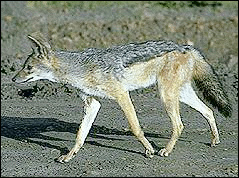

In [ ]:
from io import BytesIO
from PIL import Image

Image.open(BytesIO(r.content))

## API Practice Velib

In [ ]:
base_url = "https://velib-metropole-opendata.smovengo.cloud/opendata/Velib_Metropole"

station_info_url = f"{base_url}/station_information.json"

In [ ]:
f"{base_url}/station_information.json"

'https://velib-metropole-opendata.smovengo.cloud/opendata/Velib_Metropole/station_information.json'

In [ ]:
a = 2 

f"the value of a is: {a}"

'the value of a is: 2'


### Step 1: First API Request (GET)

We use `requests.get(url)` to send a request to an API endpoint.  
The API answers with a response object that contains status, headers, and data.


In [ ]:
# Send a GET request
response = requests.get(station_info_url)

In [ ]:
response

<Response [200]>


### Step 2: JSON Responses

Most APIs return **JSON (JavaScript Object Notation)**.  
JSON looks like a Python dictionary → it has keys and values.  
We can parse JSON with `.json()` to get a Python dict we can work with.


In [ ]:
# Parse the response into JSON (Python dict)
response.json()

{'lastUpdatedOther': 1794832331,
 'ttl': 3600,
 'data': {'stations': [{'station_id': 213688169,
    'stationCode': '16107',
    'name': 'Benjamin Godard - Victor Hugo',
    'lat': 48.865983,
    'lon': 2.275725,
    'capacity': 35,
    'station_opening_hours': None},
   {'station_id': 19179944124,
    'stationCode': '40001',
    'name': 'Hôpital Mondor',
    'lat': 48.798922410229,
    'lon': 2.4537451531298,
    'capacity': 28,
    'station_opening_hours': None},
   {'station_id': 18795078746,
    'stationCode': '32304',
    'name': 'Charcot - Benfleet',
    'lat': 48.878370277021,
    'lon': 2.440523876268,
    'capacity': 28,
    'station_opening_hours': None},
   {'station_id': 36255,
    'stationCode': '9020',
    'name': 'Toudouze - Clauzel',
    'lat': 48.87929591733507,
    'lon': 2.3373600840568547,
    'capacity': 21,
    'rental_methods': ['CREDITCARD'],
    'station_opening_hours': None},
   {'station_id': 251039991,
    'stationCode': '14111',
    'name': 'Cassini - Denfer

In [ ]:
# Parse the response into JSON (Python dict)
response.json().keys()

dict_keys(['lastUpdatedOther', 'ttl', 'data'])

In [ ]:
# Parse the response into JSON (Python dict)
response.json()["data"]

{'stations': [{'station_id': 213688169,
   'stationCode': '16107',
   'name': 'Benjamin Godard - Victor Hugo',
   'lat': 48.865983,
   'lon': 2.275725,
   'capacity': 35,
   'station_opening_hours': None},
  {'station_id': 19179944124,
   'stationCode': '40001',
   'name': 'Hôpital Mondor',
   'lat': 48.798922410229,
   'lon': 2.4537451531298,
   'capacity': 28,
   'station_opening_hours': None},
  {'station_id': 18795078746,
   'stationCode': '32304',
   'name': 'Charcot - Benfleet',
   'lat': 48.878370277021,
   'lon': 2.440523876268,
   'capacity': 28,
   'station_opening_hours': None},
  {'station_id': 36255,
   'stationCode': '9020',
   'name': 'Toudouze - Clauzel',
   'lat': 48.87929591733507,
   'lon': 2.3373600840568547,
   'capacity': 21,
   'rental_methods': ['CREDITCARD'],
   'station_opening_hours': None},
  {'station_id': 251039991,
   'stationCode': '14111',
   'name': 'Cassini - Denfert-Rochereau',
   'lat': 48.837525839067,
   'lon': 2.3360354080796,
   'capacity': 25,


In [ ]:
# Parse the response into JSON (Python dict)
response.json()["data"].keys()

dict_keys(['stations'])

In [ ]:
# Parse the response into JSON (Python dict)
len(response.json()["data"]["stations"])

1525

In [ ]:
# Parse the response into JSON (Python dict)
len(response.json()["data"]["stations"][0])

7

In [ ]:
# Parse the response into JSON (Python dict)
response.json()["data"]["stations"][0]

{'station_id': 213688169,
 'stationCode': '16107',
 'name': 'Benjamin Godard - Victor Hugo',
 'lat': 48.865983,
 'lon': 2.275725,
 'capacity': 35,
 'station_opening_hours': None}

### Step 3: Are all the dictionaries on the list the same size ?

In [ ]:
# Parse the response into JSON (Python dict)
stations = response.json()["data"]["stations"]

station_with_more_7 = 0

for station in stations: 
    if len(station) != 7:
        station_with_more_7 += 1 

In [ ]:
station_with_more_7

898

### Step 4: Add in a dataframe the content of the first response

In [ ]:
# Parse the response into JSON (Python dict)
df_stations = pd.DataFrame(response.json()["data"]["stations"])


In [ ]:
df_stations

,station_id,stationCode,name,lat,lon,capacity,station_opening_hours,rental_methods
0,213688169,16107,Benjamin Godard - Victor Hugo,48.865983,2.275725,35,None,NaN
1,19179944124,40001,Hôpital Mondor,48.798922,2.453745,28,None,NaN
2,18795078746,32304,Charcot - Benfleet,48.878370,2.440524,28,None,NaN
3,36255,9020,Toudouze - Clauzel,48.879296,2.337360,21,None,[CREDITCARD]
4,251039991,14111,Cassini - Denfert-Rochereau,48.837526,2.336035,25,None,[CREDITCARD]
...,...,...,...,...,...,...,...,...
1520,98187918,4016,Lobau - Hôtel de Ville,48.856212,2.353254,60,None,[CREDITCARD]
1521,315022587,8004,Malesherbes - Place de la Madeleine,48.870406,2.323244,67,None,[CREDITCARD]
1522,34742973,15056,Place Balard,48.836396,2.278419,22,None,[CREDITCARD]
1523,101013666,12105,Bercy - Villot,48.841795,2.376785,33,None,[CREDITCARD]


In [ ]:
import plotly.express as px
px.histogram(df_stations["capacity"])

### Step 5: Try new endpoint to get status

In [ ]:
status_endpoint = "station_status.json"

status_url = f"{base_url}/{status_endpoint}"

status_url

'https://velib-metropole-opendata.smovengo.cloud/opendata/Velib_Metropole/station_status.json'

In [ ]:
# Send a GET request
response = requests.get(status_url)
response.status_code

200

In [ ]:
# Parse the response into JSON (Python dict)
response.json().keys()

dict_keys(['lastUpdatedOther', 'ttl', 'data'])

In [ ]:
# Parse the response into JSON (Python dict)
response.json()["data"].keys()

dict_keys(['stations'])

In [ ]:
# Parse the response into JSON (Python dict)
df_status = pd.DataFrame(response.json()["data"]["stations"])

In [ ]:
df_stations.head()

,station_id,stationCode,name,lat,lon,capacity,station_opening_hours,rental_methods
0,213688169,16107,Benjamin Godard - Victor Hugo,48.865983,2.275725,35,None,NaN
1,19179944124,40001,Hôpital Mondor,48.798922,2.453745,28,None,NaN
2,18795078746,32304,Charcot - Benfleet,48.878370,2.440524,28,None,NaN
3,36255,9020,Toudouze - Clauzel,48.879296,2.337360,21,None,[CREDITCARD]
4,251039991,14111,Cassini - Denfert-Rochereau,48.837526,2.336035,25,None,[CREDITCARD]


In [ ]:
df_status.head()

,station_id,num_bikes_available,numBikesAvailable,num_bikes_available_types,num_docks_available,numDocksAvailable,is_installed,is_returning,is_renting,last_reported,stationCode,station_opening_hours
0,213688169,1,1,"[{'mechanical': 0}, {'ebike': 1}]",34,34,1,1,1,1794830803,16107,None
1,19179944124,16,16,"[{'mechanical': 8}, {'ebike': 8}]",12,12,1,1,1,1794831235,40001,None
2,18795078746,4,4,"[{'mechanical': 1}, {'ebike': 3}]",24,24,1,1,1,1794831259,32304,None
3,36255,7,7,"[{'mechanical': 4}, {'ebike': 3}]",14,14,1,1,1,1794831137,9020,None
4,251039991,11,11,"[{'mechanical': 1}, {'ebike': 10}]",13,13,1,1,1,1794831128,14111,None


In [ ]:
df_status.shape, df_stations.shape

((1525, 12), (1525, 8))

### Step 6: Merge the 2 datasets

In [ ]:
df_stations[df_stations["station_id"].isin(df_status["station_id"])]

,station_id,stationCode,name,lat,lon,capacity,station_opening_hours,rental_methods
0,213688169,16107,Benjamin Godard - Victor Hugo,48.865983,2.275725,35,None,NaN
1,19179944124,40001,Hôpital Mondor,48.798922,2.453745,28,None,NaN
2,18795078746,32304,Charcot - Benfleet,48.878370,2.440524,28,None,NaN
3,36255,9020,Toudouze - Clauzel,48.879296,2.337360,21,None,[CREDITCARD]
4,251039991,14111,Cassini - Denfert-Rochereau,48.837526,2.336035,25,None,[CREDITCARD]
...,...,...,...,...,...,...,...,...
1520,98187918,4016,Lobau - Hôtel de Ville,48.856212,2.353254,60,None,[CREDITCARD]
1521,315022587,8004,Malesherbes - Place de la Madeleine,48.870406,2.323244,67,None,[CREDITCARD]
1522,34742973,15056,Place Balard,48.836396,2.278419,22,None,[CREDITCARD]
1523,101013666,12105,Bercy - Villot,48.841795,2.376785,33,None,[CREDITCARD]


In [ ]:
df_merge = pd.merge(left=df_stations, right=df_status, on="station_id")

In [ ]:
df_merge.head()

,station_id,stationCode_x,name,lat,lon,capacity,station_opening_hours_x,rental_methods,num_bikes_available,numBikesAvailable,num_bikes_available_types,num_docks_available,numDocksAvailable,is_installed,is_returning,is_renting,last_reported,stationCode_y,station_opening_hours_y
0,213688169,16107,Benjamin Godard - Victor Hugo,48.865983,2.275725,35,None,NaN,1,1,"[{'mechanical': 0}, {'ebike': 1}]",34,34,1,1,1,1794830803,16107,None
1,19179944124,40001,Hôpital Mondor,48.798922,2.453745,28,None,NaN,16,16,"[{'mechanical': 8}, {'ebike': 8}]",12,12,1,1,1,1794831235,40001,None
2,18795078746,32304,Charcot - Benfleet,48.878370,2.440524,28,None,NaN,4,4,"[{'mechanical': 1}, {'ebike': 3}]",24,24,1,1,1,1794831259,32304,None
3,36255,9020,Toudouze - Clauzel,48.879296,2.337360,21,None,[CREDITCARD],7,7,"[{'mechanical': 4}, {'ebike': 3}]",14,14,1,1,1,1794831137,9020,None
4,251039991,14111,Cassini - Denfert-Rochereau,48.837526,2.336035,25,None,[CREDITCARD],11,11,"[{'mechanical': 1}, {'ebike': 10}]",13,13,1,1,1,1794831128,14111,None


### Step 7: Extract information contained in the type of bikes for the num_bike_available_types column

In [ ]:
df_merge["num_bikes_available_types"]

0         [{'mechanical': 0}, {'ebike': 1}]
1         [{'mechanical': 8}, {'ebike': 8}]
2         [{'mechanical': 1}, {'ebike': 3}]
3         [{'mechanical': 4}, {'ebike': 3}]
4        [{'mechanical': 1}, {'ebike': 10}]
                       ...                 
1520    [{'mechanical': 42}, {'ebike': 11}]
1521    [{'mechanical': 60}, {'ebike': 21}]
1522    [{'mechanical': 15}, {'ebike': 10}]
1523    [{'mechanical': 11}, {'ebike': 13}]
1524    [{'mechanical': 17}, {'ebike': 16}]
Name: num_bikes_available_types, Length: 1525, dtype: object

In [ ]:
# temp = [{'ebike': 3}, {'mechanical': 2}]

# for x in temp:
#     print(x)


# def get_mechanical_ebike(x):
#     presence = []
#     for elem in x: 
#         if "mechanical" or "ebike" in elem.keys():
#             presence.append(True)
#     if presence == [True, True]:
#         return True
    
# get_mechanical_ebike(temp)

# df_merge[df_merge["num_bikes_available_types"].apply(get_mechanical_ebike)].shape

In [ ]:
df_merge["mechanical"] = df_merge["num_bikes_available_types"].apply(lambda x: x[0]["mechanical"])
df_merge["ebike"] = df_merge["num_bikes_available_types"].apply(lambda x: x[1]["ebike"])

In [ ]:
df_merge

,station_id,stationCode_x,name,lat,lon,capacity,station_opening_hours_x,rental_methods,num_bikes_available,numBikesAvailable,...,num_docks_available,numDocksAvailable,is_installed,is_returning,is_renting,last_reported,stationCode_y,station_opening_hours_y,mechanical,ebike
0,213688169,16107,Benjamin Godard - Victor Hugo,48.865983,2.275725,35,None,NaN,1,1,...,34,34,1,1,1,1794830803,16107,None,0,1
1,19179944124,40001,Hôpital Mondor,48.798922,2.453745,28,None,NaN,16,16,...,12,12,1,1,1,1794831235,40001,None,8,8
2,18795078746,32304,Charcot - Benfleet,48.878370,2.440524,28,None,NaN,4,4,...,24,24,1,1,1,1794831259,32304,None,1,3
3,36255,9020,Toudouze - Clauzel,48.879296,2.337360,21,None,[CREDITCARD],7,7,...,14,14,1,1,1,1794831137,9020,None,4,3
4,251039991,14111,Cassini - Denfert-Rochereau,48.837526,2.336035,25,None,[CREDITCARD],11,11,...,13,13,1,1,1,1794831128,14111,None,1,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1520,98187918,4016,Lobau - Hôtel de Ville,48.856212,2.353254,60,None,[CREDITCARD],53,53,...,3,3,1,1,1,1794831185,4016,None,42,11
1521,315022587,8004,Malesherbes - Place de la Madeleine,48.870406,2.323244,67,None,[CREDITCARD],81,81,...,1,1,1,1,1,1794831208,8004,None,60,21
1522,34742973,15056,Place Balard,48.836396,2.278419,22,None,[CREDITCARD],25,25,...,3,3,1,1,1,1794831270,15056,None,15,10
1523,101013666,12105,Bercy - Villot,48.841795,2.376785,33,None,[CREDITCARD],24,24,...,8,8,1,1,1,1794831233,12105,None,11,13


In [ ]:
df_merge[["lat", "lon", "num_bikes_available", "name"]]

,lat,lon,num_bikes_available,name
0,48.865983,2.275725,1,Benjamin Godard - Victor Hugo
1,48.798922,2.453745,16,Hôpital Mondor
2,48.878370,2.440524,4,Charcot - Benfleet
3,48.879296,2.337360,7,Toudouze - Clauzel
4,48.837526,2.336035,11,Cassini - Denfert-Rochereau
...,...,...,...,...
1520,48.856212,2.353254,53,Lobau - Hôtel de Ville
1521,48.870406,2.323244,81,Malesherbes - Place de la Madeleine
1522,48.836396,2.278419,25,Place Balard
1523,48.841795,2.376785,24,Bercy - Villot


### Step 8: A complete graph to visualise the different stations and statuses

In [ ]:
#pip install plotly
#!pip install ipywidgets
#!jupyter nbextension enable --py widgetsnbextension

In [ ]:
import plotly.express as px

# Create the map using Plotly Express
fig = px.scatter_map(
    df_merge,
    lat="lat",
    lon="lon",
    hover_name="name",
    hover_data={
        "num_bikes_available": True,
        "num_docks_available": True,
        "lat": False, 
        "lon": False
    },
    color_discrete_sequence=["blue"],
    zoom=12,
)

# Configure the map layout
fig.update_layout(
    map_style="open-street-map",  # Use OSM without needing a Mapbox token
    map_center={"lat": 48.8566, "lon": 2.3522},  # Centered on Paris
    margin={"r":0, "t":0, "l":0, "b":0}
)

fig.show()


In [ ]:
import plotly.express as px

fig = px.scatter_map(
    df_merge,
    lat="lat",
    lon="lon",
    hover_name="name",
    hover_data={
        "num_bikes_available": True,
        "num_docks_available": True,
        "mechanical": True,
        "ebike": True,
        "lat": False,
        "lon": False
    },
    color="num_bikes_available",  # Color by number of available bikes
    color_continuous_scale="Plasma",  # Optional: color gradient
    zoom=12,
)

fig.update_layout(
    map_style="open-street-map",
    map_center={"lat": 48.8566, "lon": 2.3522},  # Paris
    margin={"r": 0, "t": 0, "l": 0, "b": 0}
)

fig.show()


## API Practice Bank and Customers

In [ ]:
# Send a GET request
base_url = 'https://sdacelo-bank-transaction-api.hf.space/'
response = requests.get(base_url)

response.text

'{"message":"Welcome to the Bank Transaction API!"}'

In [ ]:
# Send a GET request
client_endpoint = 'clients/'
response = requests.get(f"{base_url}{client_endpoint}")

response.status_code

200

In [ ]:
# Parse the response into JSON (Python dict)
len(response.json())

5000

In [ ]:
# Parse the response into JSON (Python dict)
response.json()

In [ ]:
# Parse the response into JSON (Python dict)
len(response.json()[0]["client_id"])

36

In [ ]:
# Parse the response into JSON (Python dict)
client_id = response.json()[0]["client_id"]

In [ ]:
client_id

'3eb13b90-4668-4257-bdd6-40fb06671ad1'

In [ ]:
# Send a GET request
response = requests.get(f"{base_url}{client_endpoint}{client_id}")

In [ ]:
# Parse the response into JSON (Python dict)
response.json()

In [ ]:
# Send a GET request
base_url = 'https://sdacelo-bank-transaction-api.hf.space/'
client_endpoint = 'clients/'
accounts_endpoint = 'accounts/'

clients = pd.DataFrame(requests.get(f"{base_url}{client_endpoint}").json())
accounts = pd.DataFrame(requests.get(f"{base_url}{accounts_endpoint}").json())

merged_data = pd.merge(clients, accounts, on='client_id')

In [ ]:
merged_data

In [ ]:
px.histogram(merged_data["balance"])

In [ ]:
type(response.content)

bytes

In [ ]:
# Parse the response into JSON (Python dict)
lien = "https://sdacelo-bank-transaction-api.hf.space/"+"transactions/"
response = requests.get(lien)
pd.DataFrame(response.json())

,transaction_id,account_id,amount,transaction_type,transaction_date
0,ff4a80cd-2af2-405c-abfe-0a5fea8f32d9,14766afb-d941-48dc-8761-c0b6e595bbe9,2988.32,Deposit,2025-10-03
1,63999898-8f8e-45de-b871-d97e2a6c4063,ae008f96-38e5-4380-bc4b-1044ecdbe21c,4895.21,Withdrawal,2026-03-03
2,10931ea9-106c-4088-a6dc-924d38adf03c,cf78c749-6eb0-46af-a904-2c9b3ad99151,2867.95,Transfer,2026-04-01
3,11f62fba-55bb-4176-b0cf-175183667640,19de3bfd-1b9c-4125-9ab4-d6f2cb62b998,3399.70,Deposit,2026-02-07
4,3c87cbc2-a4e4-4126-bc28-4218a9d5630e,fac5e709-ace0-4be0-aacb-54527bccd96a,4814.23,Withdrawal,2025-08-08
...,...,...,...,...,...
9995,5480636e-3a49-4aa4-85ab-64a49a072319,642f4aec-73f2-4e6f-b7bd-aaa3ccca83ff,1587.88,Withdrawal,2024-12-16
9996,b8b35de2-95b4-45c6-83e3-2b31a14ca638,a9ca63bb-d395-4056-9a6f-b69cb7b5dfae,3808.55,Deposit,2026-02-05
9997,3a6aa9dc-df3e-430c-add8-f4d8cd6e1ea0,00450287-f4d3-481e-8a5e-5b906c5cc9e4,3246.38,Deposit,2025-11-20
9998,dd42693d-e107-4042-a8bb-8f2980922983,b2a44108-eb08-47fc-9826-855c0e6545c1,52.46,Transfer,2026-07-19


In [ ]:
BASE_URL = "https://sdacelo-api-ecommerce.hf.space"

data = {
    "customer_id": "test-customer-id-bob",
    "name": "Bob",
    "email": "bob@example.com",
    "lat": 37.7749,
    "lon": -122.4194,
    "signup_date": "2025-03-10"
}

response = requests.post(f"{BASE_URL}/customers/", json=data)

print(response.status_code)
print(response.json())


200
{'message': 'Customer successfully added !'}


In [ ]:
response_get = requests.get(f"{BASE_URL}/customers/")
customers = response_get.json()

#Let's convert our JSON to a DataFrame for better visualization.
df = pd.DataFrame(customers)

display(df.tail(5))


::: {.sb-next}
**[Your turn: Working with APIs exercises →](../exercises/bitcoin.ipynb)**
:::